# Punto 3 — Membrana vibrante con PINN: parte computacional

**Problema.** Ecuación de ondas adimensional en $(0,1)^2$ con bordes fijos:

$$U_{tt}=U_{xx}+U_{yy},\qquad U(x,y,0)=\sin(\pi x)\sin(\pi y),\qquad U_t(x,y,0)=\sqrt2\pi\sin(\pi x)\sin(\pi y).$$

**Ansatz PINN:** $U_\theta(x,y,t)=\sin(\pi x)\sin(\pi y)\,a_\theta(t)$, que reduce el problema a

$$a''+2\pi^2a=0,\qquad a(0)=1,\qquad a'(0)=\sqrt2\pi .$$

**Solución analítica:** con $\omega=\sqrt2\pi$,
$$a(t)=\cos\omega t+\sin\omega t=\sqrt2\sin\!\left(\omega t+\tfrac\pi4\right).$$

**Energía mecánica** con el ansatz (integrando $\sin^2$ y $\cos^2$ sobre $[0,1]$, cada uno da $1/2$):
$$E(t)=\tfrac18\left[a'(t)^2+2\pi^2a(t)^2\right],\qquad E_{\text{exacta}}=\frac{\pi^2}{2}.$$

**Plan del notebook** (implementado en **PyTorch**):
1. Definir los dos modelos como `nn.Module`, con las derivadas temporales $a'$ y $a''$ escritas analíticamente.
2. Verificarlas con la diferenciación automática de PyTorch.
3. Construir el residuo y la función de pérdida.
4. Minimizar con `torch.optim.Adam` durante un número fijo de iteraciones; los gradientes respecto a los parámetros los calcula `backward()`.
5. Comparar con la solución analítica, cuantificar los errores y analizar la conservación de la energía.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float64)   # doble precisión: errores pequeños necesitan float64
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

PI = np.pi
OMEGA = np.sqrt(2) * PI        # frecuencia natural del modo (1,1)
OMEGA2 = 2 * PI**2             # omega^2
V0 = np.sqrt(2) * PI           # a'(0)
E_EXACT = PI**2 / 2            # energía exacta

T_TRAIN = 2.0                  # intervalo de entrenamiento [0, 2]  (~1.4 periodos)
T_EVAL = 3.0                   # evaluamos hasta t = 3 para ver extrapolación
N_COL = 200                    # puntos de colocación
t_col = torch.linspace(0.0, T_TRAIN, N_COL)
t_0 = torch.zeros(1)

print(f"PyTorch {torch.__version__}")
print(f"omega = {OMEGA:.6f},  periodo = {2*PI/OMEGA:.4f},  E_exacta = {E_EXACT:.6f}")

PyTorch 2.15.0+cu132
omega = 4.442883,  periodo = 1.4142,  E_exacta = 4.934802


## 1. Solución analítica

In [2]:
def a_exact(t):
    return np.cos(OMEGA * t) + np.sin(OMEGA * t)

## 2. Modelos y sus derivadas analíticas

Cada modelo es un `nn.Module` cuyos parámetros son `nn.Parameter`, de modo que PyTorch los entrena. El método `forward(t)` devuelve $a$, $a'$ y $a''$, con las derivadas temporales escritas a mano a partir de la regla de la cadena.

**Modelo A** — una capa, dos neuronas sinusoidales, con $\phi_j=w_jt+b_j$:

$$a=\sum_j A_j\sin\phi_j,\qquad a'=\sum_jA_jw_j\cos\phi_j,\qquad a''=-\sum_jA_jw_j^2\sin\phi_j .$$

Parámetros: $\theta=(A_1,A_2,w_1,w_2,b_1,b_2)$, inicializados con $A_j\sim\mathcal N(0,1)$, $w_j\sim\mathcal U(1,8)$ y $b_j\sim\mathcal U(-\pi,\pi)$.

In [3]:
class ModeloA(nn.Module):
    def __init__(self, gen):
        super().__init__()
        self.A = nn.Parameter(torch.randn(2, generator=gen))
        self.w = nn.Parameter(1 + 7 * torch.rand(2, generator=gen))
        self.b = nn.Parameter(PI * (2 * torch.rand(2, generator=gen) - 1))

    def forward(self, t):
        phi = t[:, None] * self.w + self.b                  # (N, 2)
        a   =  (self.A * torch.sin(phi)).sum(dim=1)
        da  =  (self.A * self.w * torch.cos(phi)).sum(dim=1)
        d2a = -(self.A * self.w**2 * torch.sin(phi)).sum(dim=1)
        return a, da, d2a

**Modelo B** — dos capas, una neurona por capa, con $u=w_1t+b_1$ y $v=w_2h_1+b_2$:

$$h_1=\sin u,\qquad h_1'=w_1\cos u,\qquad h_1''=-w_1^2\sin u,$$

$$a=A\sin v,\qquad a'=A\cos v\;w_2h_1',\qquad a''=-A\sin v\,(w_2h_1')^2+A\cos v\;w_2h_1'' .$$

Parámetros: $\theta=(w_1,b_1,w_2,b_2,A)$, inicializados con $w_1\sim\mathcal U(1,8)$, $b_1\sim\mathcal U(-\pi,\pi)$, $w_2\sim\mathcal U(0.1,3)$, $b_2\sim\mathcal U(-1,1)$ y $A\sim\mathcal N(0,1)$.

In [4]:
class ModeloB(nn.Module):
    def __init__(self, gen):
        super().__init__()
        u01 = lambda: torch.rand(1, generator=gen)
        self.w1 = nn.Parameter(1 + 7 * u01())
        self.b1 = nn.Parameter(PI * (2 * u01() - 1))
        self.w2 = nn.Parameter(0.1 + 2.9 * u01())
        self.b2 = nn.Parameter(2 * u01() - 1)
        self.A  = nn.Parameter(torch.randn(1, generator=gen))

    def forward(self, t):
        u = self.w1 * t + self.b1
        h1, dh1, d2h1 = torch.sin(u), self.w1 * torch.cos(u), -self.w1**2 * torch.sin(u)
        v = self.w2 * h1 + self.b2
        a   = self.A * torch.sin(v)
        da  = self.A * torch.cos(v) * self.w2 * dh1
        d2a = -self.A * torch.sin(v) * (self.w2 * dh1)**2 + self.A * torch.cos(v) * self.w2 * d2h1
        return a, da, d2a

### Verificación de las derivadas con diferenciación automática

Comparamos las derivadas $a'$ y $a''$ escritas a mano con las que calcula PyTorch derivando $a(t)$ respecto a $t$ con `torch.autograd.grad`. Para la segunda derivada se usa `create_graph=True`, que permite derivar el resultado de la primera derivada. Si las fórmulas analíticas son correctas, ambas coinciden a precisión de máquina ($\sim10^{-13}$).

In [5]:
def check_derivatives(model):
    t = torch.linspace(0.0, T_TRAIN, 50, requires_grad=True)
    a, da, d2a = model(t)
    da_ad  = torch.autograd.grad(a.sum(), t, create_graph=True)[0]
    d2a_ad = torch.autograd.grad(da_ad.sum(), t)[0]
    return (da - da_ad).abs().max().item(), (d2a - d2a_ad).abs().max().item()

gen = torch.Generator().manual_seed(0)
for name, m in [("Modelo A", ModeloA(gen)), ("Modelo B", ModeloB(gen))]:
    e1, e2 = check_derivatives(m)
    print(f"{name}:  max|a'_analítica - a'_autograd| = {e1:.1e}   max|a''_analítica - a''_autograd| = {e2:.1e}")

Modelo A:  max|a'_analítica - a'_autograd| = 8.9e-16   max|a''_analítica - a''_autograd| = 1.4e-14
Modelo B:  max|a'_analítica - a'_autograd| = 4.4e-16   max|a''_analítica - a''_autograd| = 1.8e-15


## 3. Residuo físico y función de pérdida

Residuo de la EDO:
$$r_\theta(t)=a_\theta''(t)+2\pi^2a_\theta(t).$$

Pérdida:
$$J(\theta)=\frac1N\sum_{i=1}^N\left(\frac{r_\theta(t_i)}{\omega^2}\right)^2+\bigl[a_\theta(0)-1\bigr]^2+\left(\frac{a_\theta'(0)-\sqrt2\pi}{\omega}\right)^2 .$$

Se divide el residuo por $\omega^2$ y la velocidad inicial por $\omega$ para que los tres términos tengan escala comparable. Esto equivale a escoger los pesos $\omega_{ec}=1/\omega^4$, $\omega_0=1$ y $\omega_1=1/\omega^2$.

No hay término de frontera: el ansatz cumple $U=0$ en los bordes por construcción.

In [6]:
def residual(model, t):
    a, _, d2a = model(t)
    return d2a + OMEGA2 * a

def loss_fn(model):
    r = residual(model, t_col)
    a0, da0, _ = model(t_0)
    J_ec = torch.mean((r / OMEGA2)**2)
    J_a0 = (a0[0] - 1.0)**2
    J_v0 = ((da0[0] - V0) / OMEGA)**2
    return J_ec + J_a0 + J_v0

def energy(model, t):
    a, da, _ = model(t)
    return 0.125 * (da**2 + OMEGA2 * a**2)

## 4. Optimización con Adam

Usamos `torch.optim.Adam` con un **número fijo de iteraciones** `N_ITER = 5000`, igual para ambos modelos y para todas las inicializaciones; no hay ningún criterio de parada. La tasa de aprendizaje también sigue un calendario fijo: `ExponentialLR` la hace decaer de $\eta_0=5\times10^{-2}$ a $\eta_f=10^{-5}$ a lo largo de las `N_ITER` iteraciones.

En cada iteración:
1. `loss_fn(model)` evalúa $J(\theta)$, usando las derivadas temporales analíticas dentro del residuo;
2. `loss.backward()` calcula $\nabla_\theta J$ por diferenciación automática (retropropagación);
3. `optimizer.step()` aplica la actualización de Adam.

Las funciones de activación sinusoidales generan muchos mínimos locales en las frecuencias $w$. Por eso repetimos el entrenamiento desde varias inicializaciones aleatorias, todas con las mismas `N_ITER` iteraciones, y nos quedamos con la de menor pérdida final.

In [7]:
N_ITER = 5000             # número fijo de iteraciones de Adam
LR0, LR_END = 5e-2, 1e-5  # tasa de aprendizaje inicial y final

def train_one(model):
    opt = torch.optim.Adam(model.parameters(), lr=LR0)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(LR_END / LR0) ** (1 / N_ITER))
    hist = np.empty(N_ITER)
    for k in range(N_ITER):
        opt.zero_grad()
        loss = loss_fn(model)
        loss.backward()
        opt.step()
        sched.step()
        hist[k] = loss.item()
    return np.append(hist, loss_fn(model).item())   # pérdida inicial ... pérdida final

def train(ModelClass, n_restarts, seed):
    gen = torch.Generator().manual_seed(seed)
    models, hists = [], []
    for _ in range(n_restarts):
        m = ModelClass(gen)
        hists.append(train_one(m)); models.append(m)
    finals = np.array([h[-1] for h in hists])
    best = int(np.argmin(finals))
    return models[best], hists[best], finals

mA, histA, finalsA = train(ModeloA, n_restarts=10, seed=1)
mB, histB, finalsB = train(ModeloB, n_restarts=20, seed=2)

for name, h, f in [("Modelo A", histA, finalsA), ("Modelo B", histB, finalsB)]:
    print(f"{name}: {N_ITER} iteraciones,  J final (mejor) = {h[-1]:.3e},  "
          f"J final en las {len(f)} inicializaciones: mediana = {np.median(f):.1e}")

Modelo A: 5000 iteraciones,  J final (mejor) = 1.156e-31,  J final en las 10 inicializaciones: mediana = 1.1e-09
Modelo B: 5000 iteraciones,  J final (mejor) = 1.674e-03,  J final en las 20 inicializaciones: mediana = 1.0e-02


### Parámetros obtenidos

In [8]:
p = {k: v.detach().numpy() for k, v in mA.named_parameters()}
print(f"Modelo A        (exacta: amplitud sqrt(2) = {np.sqrt(2):.6f}, w = sqrt(2) pi = {OMEGA:.6f}, fase pi/4 = {PI/4:.6f})")
for j in range(2):
    print(f"  neurona {j+1}:  A = {p['A'][j]: .6f}   w = {p['w'][j]:.6f}   b = {p['b'][j]: .6f}")

q = {k: v.item() for k, v in mB.named_parameters()}
print("\nModelo B")
print(f"  w1 = {q['w1']:.6f}   (sqrt(2) pi = {OMEGA:.6f})")
print(f"  b1 = {q['b1']:.6f}   w2 = {q['w2']:.6f}   b2 = {q['b2']:.2e}   A = {q['A']:.6f}")
print(f"  A*w2 = {q['A']*q['w2']:.6f}   (si la segunda capa fuera lineal, |A*w2| -> sqrt(2) = {np.sqrt(2):.6f})")

Modelo A        (exacta: amplitud sqrt(2) = 1.414214, w = sqrt(2) pi = 4.442883, fase pi/4 = 0.785398)
  neurona 1:  A = -0.000000   w = 6.038285   b =  3.160156
  neurona 2:  A = -1.414214   w = 4.442883   b = -2.356194

Modelo B
  w1 = 4.447238   (sqrt(2) pi = 4.442883)
  b1 = 0.774241   w2 = 0.351055   b2 = 6.62e-04   A = 4.093835
  A*w2 = 1.437162   (si la segunda capa fuera lineal, |A*w2| -> sqrt(2) = 1.414214)


## 5. Comparación con la solución analítica

Entrenamos en $[0,2]$ (fondo blanco) y evaluamos también en $[2,3]$ (fondo gris) para probar la extrapolación.

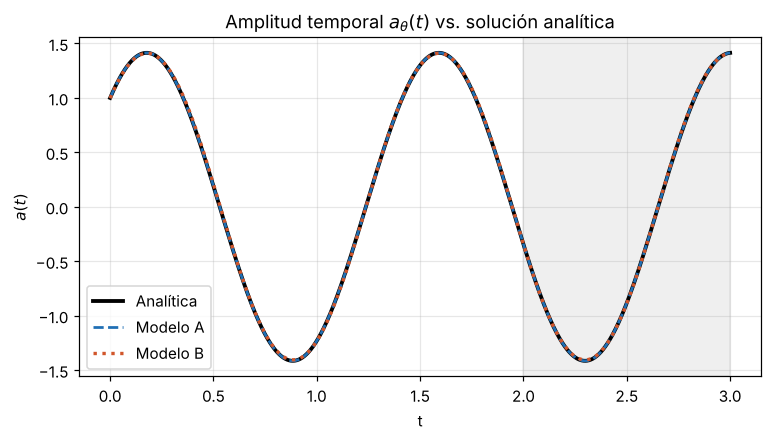

In [9]:
@torch.no_grad()
def evaluate(model, t_np):
    # Devuelve a, a', a'', residuo y energía como arreglos de NumPy
    t = torch.from_numpy(t_np)
    a, da, d2a = model(t)
    r = d2a + OMEGA2 * a
    E = 0.125 * (da**2 + OMEGA2 * a**2)
    return {k: v.numpy() for k, v in dict(a=a, da=da, d2a=d2a, r=r, E=E).items()}

t_all = np.linspace(0, T_EVAL, 3001)
aE = a_exact(t_all)
evA, evB = evaluate(mA, t_all), evaluate(mB, t_all)
cA, cB = "#1f6fb4", "#d1562b"

def shade(ax):
    ax.axvspan(T_TRAIN, T_EVAL, color="gray", alpha=0.12)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t_all, aE, "k", lw=2.5, label="Analítica")
ax.plot(t_all, evA["a"], "--", color=cA, lw=1.8, label="Modelo A")
ax.plot(t_all, evB["a"], ":", color=cB, lw=2.2, label="Modelo B")
shade(ax)
ax.set(xlabel="t", ylabel=r"$a(t)$", title=r"Amplitud temporal $a_\theta(t)$ vs. solución analítica")
ax.legend(); plt.show()

Para distinguir las curvas que se superponen, miramos el error en escala logarítmica.

Como $U_\theta-U=\sin(\pi x)\sin(\pi y)\,(a_\theta-a)$ y el máximo del producto de senos es 1, el error de $a(t)$ es el error máximo de $U$ sobre la membrana.

## 6. Cuantificación de errores

In [11]:
t_tr = np.linspace(0, T_TRAIN, 2001)
t_ex = np.linspace(T_TRAIN, T_EVAL, 1001)

def metrics(model):
    tr, ex, z = evaluate(model, t_tr), evaluate(model, t_ex), evaluate(model, np.zeros(1))
    a_tr_ex, a_ex_ex = a_exact(t_tr), a_exact(t_ex)
    return {
        "J final": loss_fn(model).item(),
        "Error L2 rel. [0,2]": np.linalg.norm(tr["a"] - a_tr_ex) / np.linalg.norm(a_tr_ex),
        "Error máx. [0,2]": np.max(np.abs(tr["a"] - a_tr_ex)),
        "Error L2 rel. [2,3] (extrap.)": np.linalg.norm(ex["a"] - a_ex_ex) / np.linalg.norm(a_ex_ex),
        "RMS residuo": np.sqrt(np.mean(tr["r"]**2)),
        "|a(0) - 1|": abs(z["a"][0] - 1),
        "|a'(0) - sqrt2 pi|": abs(z["da"][0] - V0),
        "Deriva máx. rel. de E": np.max(np.abs(tr["E"] - E_EXACT)) / E_EXACT,
    }

tabla = pd.DataFrame({"Modelo A": metrics(mA), "Modelo B": metrics(mB)})
tabla.style.format("{:.2e}")

,Modelo A,Modelo B
J final,1.16e-31,1.67e-03
"Error L2 rel. [0,2]",2.98e-16,9.36e-03
"Error máx. [0,2]",6.66e-16,2.21e-02
"Error L2 rel. [2,3] (extrap.)",8.37e-16,5.73e-03
RMS residuo,3.26e-15,8.04e-01
|a(0) - 1|,2.22e-16,2.60e-03
|a'(0) - sqrt2 pi|,8.88e-16,1.10e-02
Deriva máx. rel. de E,1.08e-15,3.48e-02


## 7. Conservación de la energía

Derivando la expresión de la energía con el ansatz:

$$\frac{dE}{dt}=\frac14\,a'\left(a''+2\pi^2a\right)=\frac14\,a'(t)\,r_\theta(t).$$

**La energía se conserva exactamente si y solo si el residuo es nulo.** Por tanto, la deriva de $E(t)$ es un diagnóstico de qué tan bien la red satisface la física.

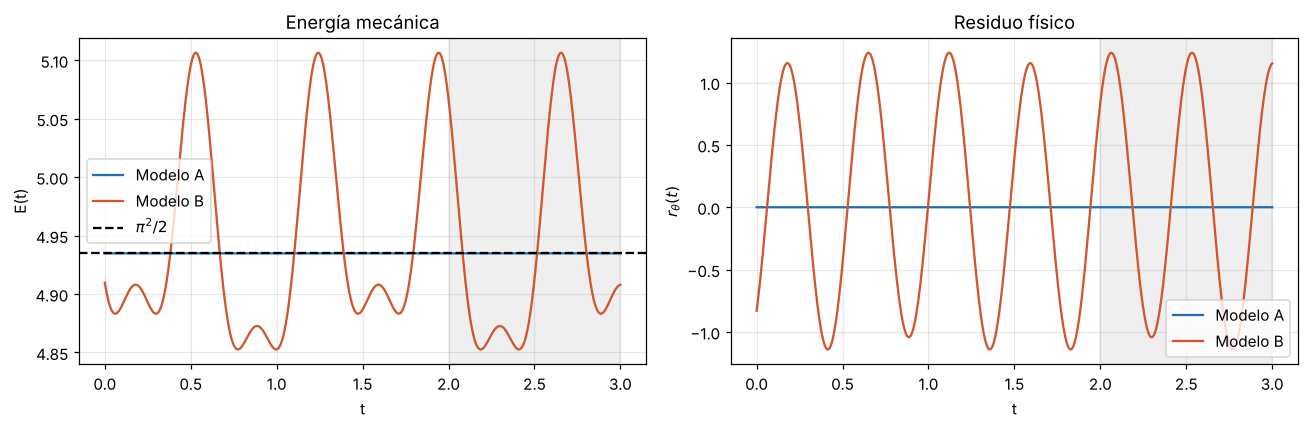

Modelo B: max|dE/dt (autograd) - (1/4) a' r| = 1.1e-14


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t_all, evA["E"], color=cA, label="Modelo A")
ax[0].plot(t_all, evB["E"], color=cB, label="Modelo B")
ax[0].axhline(E_EXACT, color="k", ls="--", label=r"$\pi^2/2$")
shade(ax[0]); ax[0].set(xlabel="t", ylabel="E(t)", title="Energía mecánica"); ax[0].legend()

ax[1].plot(t_all, evA["r"], color=cA, label="Modelo A")
ax[1].plot(t_all, evB["r"], color=cB, label="Modelo B")
shade(ax[1]); ax[1].set(xlabel="t", ylabel=r"$r_\theta(t)$", title="Residuo físico"); ax[1].legend()
plt.tight_layout(); plt.show()

# Verificación con autograd de dE/dt = (1/4) a' r  (Modelo B)
t = torch.linspace(0.05, 1.95, 400, requires_grad=True)
dEdt_ad = torch.autograd.grad(energy(mB, t).sum(), t)[0]
a, da, d2a = mB(t)
dEdt_th = 0.25 * da * (d2a + OMEGA2 * a)
print(f"Modelo B: max|dE/dt (autograd) - (1/4) a' r| = {(dEdt_ad - dEdt_th).abs().max().item():.1e}")

## 8. Convergencia de la pérdida

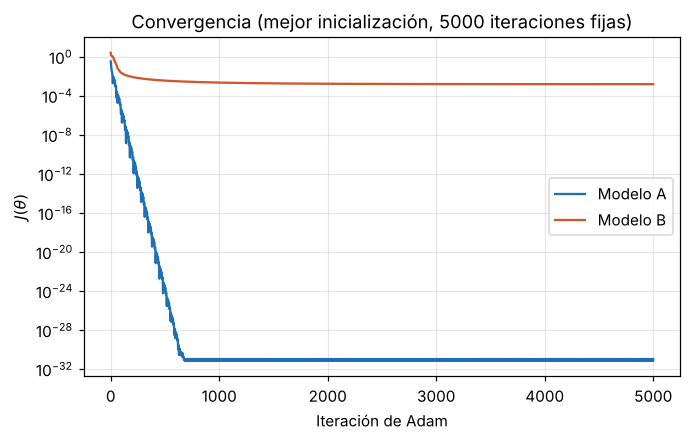

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(histA, color=cA, label="Modelo A")
ax.semilogy(histB, color=cB, label="Modelo B")
ax.set(xlabel="Iteración de Adam", ylabel=r"$J(\theta)$",
       title=f"Convergencia (mejor inicialización, {N_ITER} iteraciones fijas)")
ax.legend(); plt.show()

## 9. La membrana completa

Reconstruimos $U_\theta(x,y,t)$ en $t=0.6$ y mostramos la solución analítica junto al error de cada modelo.

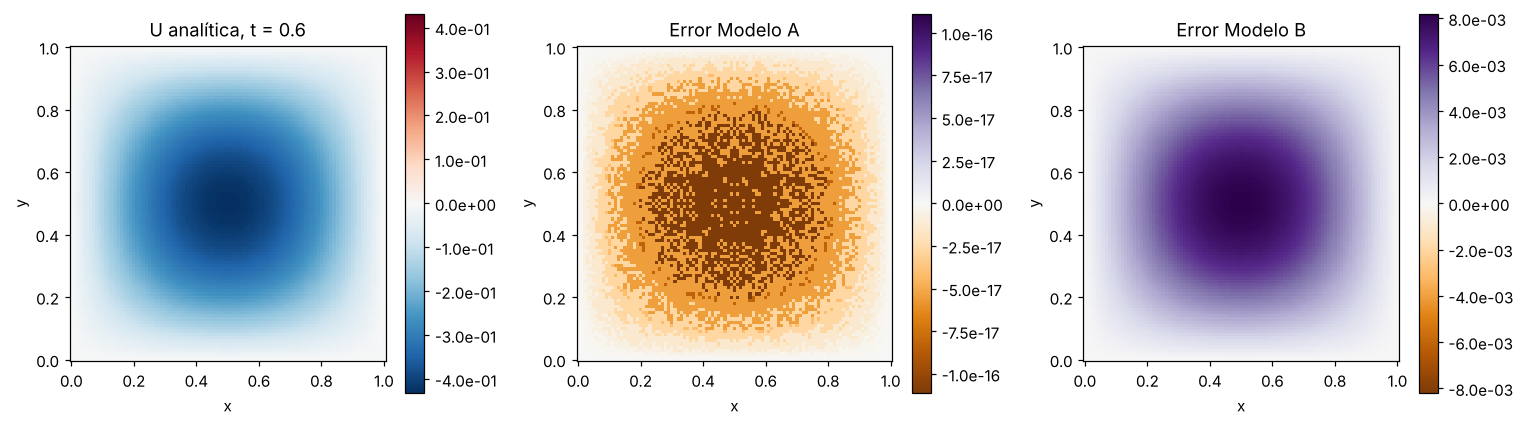

In [14]:
ts = 0.6
x = np.linspace(0, 1, 101); X, Y = np.meshgrid(x, x)
S = np.sin(PI * X) * np.sin(PI * Y)
UE = S * a_exact(ts)
UA = S * evaluate(mA, np.array([ts]))["a"][0]
UB = S * evaluate(mB, np.array([ts]))["a"][0]

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for axi, Z, title, cmap in [(ax[0], UE, f"U analítica, t = {ts}", "RdBu_r"),
                            (ax[1], UA - UE, "Error Modelo A", "PuOr"),
                            (ax[2], UB - UE, "Error Modelo B", "PuOr")]:
    vmax = np.max(np.abs(Z)) + 1e-30
    im = axi.pcolormesh(X, Y, Z, cmap=cmap, vmin=-vmax, vmax=vmax, shading="auto")
    axi.set(title=title, xlabel="x", ylabel="y", aspect="equal"); axi.grid(False)
    fig.colorbar(im, ax=axi, format="%.1e")
plt.tight_layout(); plt.show()

## 10. Análisis de resultados

Con el mismo número de iteraciones de Adam (5000) y el mismo calendario de tasa de aprendizaje, los dos modelos terminan en situaciones muy distintas. El Modelo A reproduce la solución analítica a precisión de máquina: su pérdida final es del orden de $10^{-31}$, el error $L_2$ relativo de $a(t)$ es de $3\times10^{-16}$ y la energía se mantiene constante en $\pi^2/2$ con una deriva relativa de $10^{-15}$. El resultado es además robusto, porque la mediana de la pérdida sobre las 10 inicializaciones ya es del orden de $10^{-9}$. La razón está en el residuo, $r_\theta=\sum_jA_j(2\pi^2-w_j^2)\sin(w_jt+b_j)$, que solo se anula si cada neurona activa oscila a la frecuencia natural $\sqrt2\pi$ o si su amplitud es cero. Eso es justamente lo que encontró el optimizador: la segunda neurona tomó $A=-\sqrt2$, $w=\sqrt2\pi$ y $b=-3\pi/4$, y como $-\sqrt2\sin(\omega t-3\pi/4)=\sqrt2\sin(\omega t+\pi/4)$, coincide exactamente con la solución analítica; la primera neurona se apagó con $A_1=0$, de modo que su frecuencia quedó irrelevante. La solución exacta pertenece al espacio de funciones del modelo y le basta una neurona, lo que también explica que el error no crezca al extrapolar a $t\in[2,3]$: el modelo aprendió la ley física y no solo los puntos de entrenamiento.

El Modelo B, en cambio, se queda con un error cercano al 1 %: error $L_2$ relativo de $9\times10^{-3}$, error máximo de $2\times10^{-2}$ sobre la membrana y una energía que oscila con una deriva de hasta el 3.5 %. La causa es estructural. La salida $A\sin(w_2\sin u+b_2)$ contiene, además del seno de la frecuencia fundamental, armónicos $\sin3u,\sin5u,\dots$ (y, si $b_2\neq0$, una constante y armónicos pares), y ninguno de ellos satisface $a''+2\pi^2a=0$, por lo que el residuo no puede anularse para ningún valor finito de los parámetros. La única forma de acercarse a la solución es linealizar la segunda capa, $\sin(w_2h_1)\approx w_2h_1$, llevando $b_2\to0$ y $w_2\to0$ mientras $A$ crece para mantener $|Aw_2|\approx\sqrt2$. El optimizador siguió ese camino, con $b_2\approx7\times10^{-4}$ y $Aw_2\approx1.44$, pero en 5000 iteraciones solo redujo $w_2$ hasta $0.35$. El término cúbico que sobrevive, $-(w_2h_1)^3/6$, produce un tercer armónico de amplitud aproximada $\sqrt2\,w_2^2/24\approx7\times10^{-3}$, consistente con el error medido, y es la oscilación rápida que se observa en el residuo y en la energía. Como el óptimo solo se alcanza en el límite $w_2\to0$, $A\to\infty$, el problema está mal condicionado: la pérdida desciende lentamente y con más iteraciones seguiría bajando, pero sin llegar nunca a cero.

En conclusión, la calidad de la PINN la decide si la arquitectura puede representar la solución, no la profundidad de la red. El Modelo A, de una sola capa, contiene la solución exacta porque su función de activación tiene la misma forma que la solución física, mientras que el Modelo B, más profundo, introduce armónicos espurios que solo puede suprimir en un límite degenerado de sus parámetros. La conservación de la energía, que con el ansatz cumple $dE/dt=\tfrac14a'r_\theta$ (verificado también con diferenciación automática), ofrece una verificación física independiente de este diagnóstico: la energía del Modelo A es constante porque su residuo es nulo, y la del Modelo B oscila exactamente donde su residuo no lo es.